In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np

In [2]:
from scipy.integrate import solve_ivp

In [3]:
class CoastingCarEnv(gym.Env):
    def __init__(self):
        super(CoastingCarEnv, self).__init__()

        # Define action and observation spaces
        self.action_space = spaces.Discrete(2)  # For simplicity, 0 for no action, 1 for braking
        self.observation_space = spaces.Box(low=np.array([0, 0, 0]), high=np.array([100, 100, 100]), dtype=np.float32)

        # Initialize state variables
        self.x = 0  # position of the car
        self.v = 10  # initial velocity of the car
        self.a = 0  # acceleration of the car
        self.m = 100  # stop sign position
        self.t = 0  # clock variable

        # Constants
        self.b = 1  # braking capabilities
        self.ep = 0.1  # reaction time
        

    def step(self, action):

        if action == 1:  # Brake
            self.a = -self.b
        else:
            self.a = 0
        
        def model(t, y):
            x, v, t = y
            dydt = [v, self.a, 1]
            return dydt

        def zero_velocity_event(t_ode, y):
            v_state = y[1] # v is the second element (index 1) of the state vector y
            return v_state

        # We want the solver to stop when the event is found (terminal=True)
        # and we want it to detect the event regardless of the direction (direction=0)
        zero_velocity_event.terminal = True
        zero_velocity_event.direction = 0
        
        # 2. Solve the ODEs with the event
        # The integration will stop at t=self.t+1 OR when v=0, whichever comes first.
        sol = solve_ivp(
            model, 
            (self.t, self.t + 1), 
            [self.x, self.v, self.t], 
            method='RK45', 
            events=zero_velocity_event
        )
    
        # Update the state variables based on the integration result
        self.x = sol.y[0, -1]
        self.v = sol.y[1, -1]
        self.t = sol.y[2, -1] if self.t < sol.y[2, -1] else self.t + 1

        # Restriction
        if self.v < 0:
            self.v = 0

        # if self.t > self.ep:
        #     self.t = self.ep

        # Check if the car has reached the stop sign
        done = self.x >= self.m
        # print('done: ', done)

        #------------------------------------------
        if self.v**2 <= 2*self.b*(self.m-self.x):
          reward = 1
        else:
          # print(self.v**2, 2*self.b*(self.m-self.x))
          reward = -10
        #--------------------------------------------

        return np.array([self.x, self.v, self.t]), reward, done, done, {}

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        # Reset state variables
        self.x = 0
        self.v = 10
        self.a = 0
        self.t = 0

        return np.array([self.x, self.v, self.t])

    def render(self, mode='human'):
        print(f"Position: {self.x}, Velocity: {self.v}, Time: {self.t}")

    def close(self):
        pass



In [4]:
gym.register(
    id = "SpeedLimit-v0",
    entry_point = CoastingCarEnv,
    max_episode_steps=10000
)

In [5]:
from collections import defaultdict
from tqdm import tqdm

In [12]:
from collections import defaultdict
import numpy as np
import gymnasium as gym

# Define the Agent class with the necessary fixes
class SpeedLimitAgent:
    def __init__(
        self,
        env: gym.Env,
        learning_rate: float,
        initial_epsilon: float,
        epsilon_decay: float,
        final_epsilon: float,
        discount_factor: float = 0.95,
    ):
        self.env = env
        
        # --- FIX 1: Define Discretization Bins ---
        # Based on your observation space: [x, v, t]
        # x: 0 to 100 (or 1000 from env, let's use 100 for now, adjust as needed)
        # v: 0 to 100
        # t: 0 to 100
        # The number of bins determines the size of the Q-table.
        self.num_bins = (10, 10, 10) # 10 bins for x, 10 for v, 10 for t
        self.obs_low = self.env.observation_space.low
        self.obs_high = self.env.observation_space.high
        
        # Q-table: maps (discrete_state_tuple, action) to expected reward
        self.q_values = defaultdict(lambda: np.zeros(env.action_space.n))

        self.lr = learning_rate
        self.discount_factor = discount_factor

        self.epsilon = initial_epsilon
        self.epsilon_decay = epsilon_decay
        self.final_epsilon = final_epsilon
        self.training_error = []

    # --- FIX 2: Add Discretization Method ---
    def get_discrete_state(self, observation: np.ndarray) -> tuple:
        """Converts a continuous observation array into a discrete, hashable tuple."""
        # Ensure observation is within bounds (clip it if necessary)
        # The max value in your env is 100 for all, but x_max is 1000 in __init__
        # Let's use the actual max from the environment's __init__ for x (1000)
        # Assuming you meant to update the observation_space high to [1000, 100, 100]
        
        # For simplicity, we'll use the hardcoded bounds from the environment's __init__
        # [x, v, t]
        
        # Position (x): 0 to 1000
        x_scaled = (observation[0] - 0) / 1000.0
        
        # Velocity (v): 0 to 100
        v_scaled = (observation[1] - 0) / 100.0
        
        # Time (t): 0 to 100
        t_scaled = (observation[2] - 0) / 100.0
        
        # Clip to [0, 1] and map to bin indices [0, num_bins - 1]
        x_bin = np.clip(np.floor(x_scaled * self.num_bins[0]), 0, self.num_bins[0] - 1).astype(int)
        v_bin = np.clip(np.floor(v_scaled * self.num_bins[1]), 0, self.num_bins[1] - 1).astype(int)
        t_bin = np.clip(np.floor(t_scaled * self.num_bins[2]), 0, self.num_bins[2] - 1).astype(int)
        
        return (x_bin, v_bin, t_bin)

    def get_action(self, obs: np.ndarray) -> int:
        """Choose an action using epsilon-greedy strategy."""
        discrete_obs = self.get_discrete_state(obs) # Use discrete state
        
        if np.random.random() < self.epsilon:
            return self.env.action_space.sample()
        else:
            # --- FIX 3: Use discrete_obs as the key ---
            return int(np.argmax(self.q_values[discrete_obs]))

    def update(
        self,
        obs: np.ndarray,
        action: int,
        reward: float,
        terminated: bool,
        next_obs: np.ndarray,
    ):
        """Update Q-value based on experience."""
        # --- FIX 4: Convert continuous observations to discrete states ---
        discrete_obs = self.get_discrete_state(obs)
        discrete_next_obs = self.get_discrete_state(next_obs)
        
        # What's the best we could do from the next state?
        # --- FIX 5: Use discrete_next_obs as the key ---
        future_q_value = (not terminated) * np.max(self.q_values[discrete_next_obs])

        # What should the Q-value be? (Bellman equation)
        target = reward + self.discount_factor * future_q_value

        # How wrong was our current estimate?
        # --- FIX 6: Use discrete_obs as the key ---
        temporal_difference = target - self.q_values[discrete_obs][action]

        # Update our estimate in the direction of the error
        # --- FIX 7: Use discrete_obs as the key ---
        self.q_values[discrete_obs][action] = (
            self.q_values[discrete_obs][action] + self.lr * temporal_difference
        )

        self.training_error.append(temporal_difference)

    def decay_epsilon(self):
        """Reduce exploration rate after each episode."""
        self.epsilon = max(self.final_epsilon, self.epsilon - self.epsilon_decay)

In [13]:
# Training hyperparameters
learning_rate = 0.01        # How fast to learn (higher = faster but less stable)
n_episodes = 100        # Number of hands to practice
start_epsilon = 1.0         # Start with 100% random actions
epsilon_decay = start_epsilon / (n_episodes / 2)  # Reduce exploration over time
final_epsilon = 0.1         # Always keep some exploration

In [14]:
gym.register(
    id = "SpeedLimit-v0",
    entry_point = CoastingCarEnv,
    max_episode_steps=10000
)

d:\Reinforcement learning\kyx_parser\.venv\Lib\site-packages\gymnasium\envs\registration.py:636: UserWarning: WARN: Overriding environment SpeedLimit-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")


In [15]:
env = gym.make("SpeedLimit-v0")


In [16]:
agent = SpeedLimitAgent(
    env=env,
    learning_rate=learning_rate,
    initial_epsilon=start_epsilon,
    epsilon_decay=epsilon_decay,
    final_epsilon=final_epsilon,
)

In [ ]:
rewards = []
ep_lengths = []

for episode in tqdm(range(n_episodes)):
    # Start a new hand
    obs = env.reset()
    done = False
    ep_reward = 0
    ep_length = 0

    # Play one complete hand
    while not done:
        # Agent chooses action (initially random, gradually more intelligent)
        action = agent.get_action(obs)

        # Take action and observe result
        next_obs, reward, terminated, truncated, info = env.step(action)
        ep_reward += reward
        ep_length += 1
        
        # print(obs, next_obs)

        # Learn from this experience
        agent.update(obs, action, reward, done, next_obs)

        # Move to next state
        done = terminated or truncated
        obs = next_obs

    # Reduce exploration rate (agent becomes less random over time)
    agent.decay_epsilon()

    rewards.append(ep_reward)
    ep_lengths.append(ep_length)

  0%|          | 0/100 [00:00<?, ?it/s]

d:\Reinforcement learning\kyx_parser\.venv\Lib\site-packages\gymnasium\utils\passive_env_checker.py:188: UserWarning: WARN: The result returned by `env.reset()` was not a tuple of the form `(obs, info)`, where `obs` is a observation and `info` is a dictionary containing additional information. Actual type: `<class 'numpy.ndarray'>`
  logger.warn(
d:\Reinforcement learning\kyx_parser\.venv\Lib\site-packages\gymnasium\utils\passive_env_checker.py:134: UserWarning: WARN: The obs returned by the `step()` method was expecting numpy array dtype to be float32, actual type: float64
  logger.warn(
d:\Reinforcement learning\kyx_parser\.venv\Lib\site-packages\gymnasium\utils\passive_env_checker.py:158: UserWarning: WARN: The obs returned by the `step()` method is not within the observation space.
  logger.warn(f"{pre} is not within the observation space.")
 49%|████▉     | 49/100 [01:01<01:49,  2.15s/it]

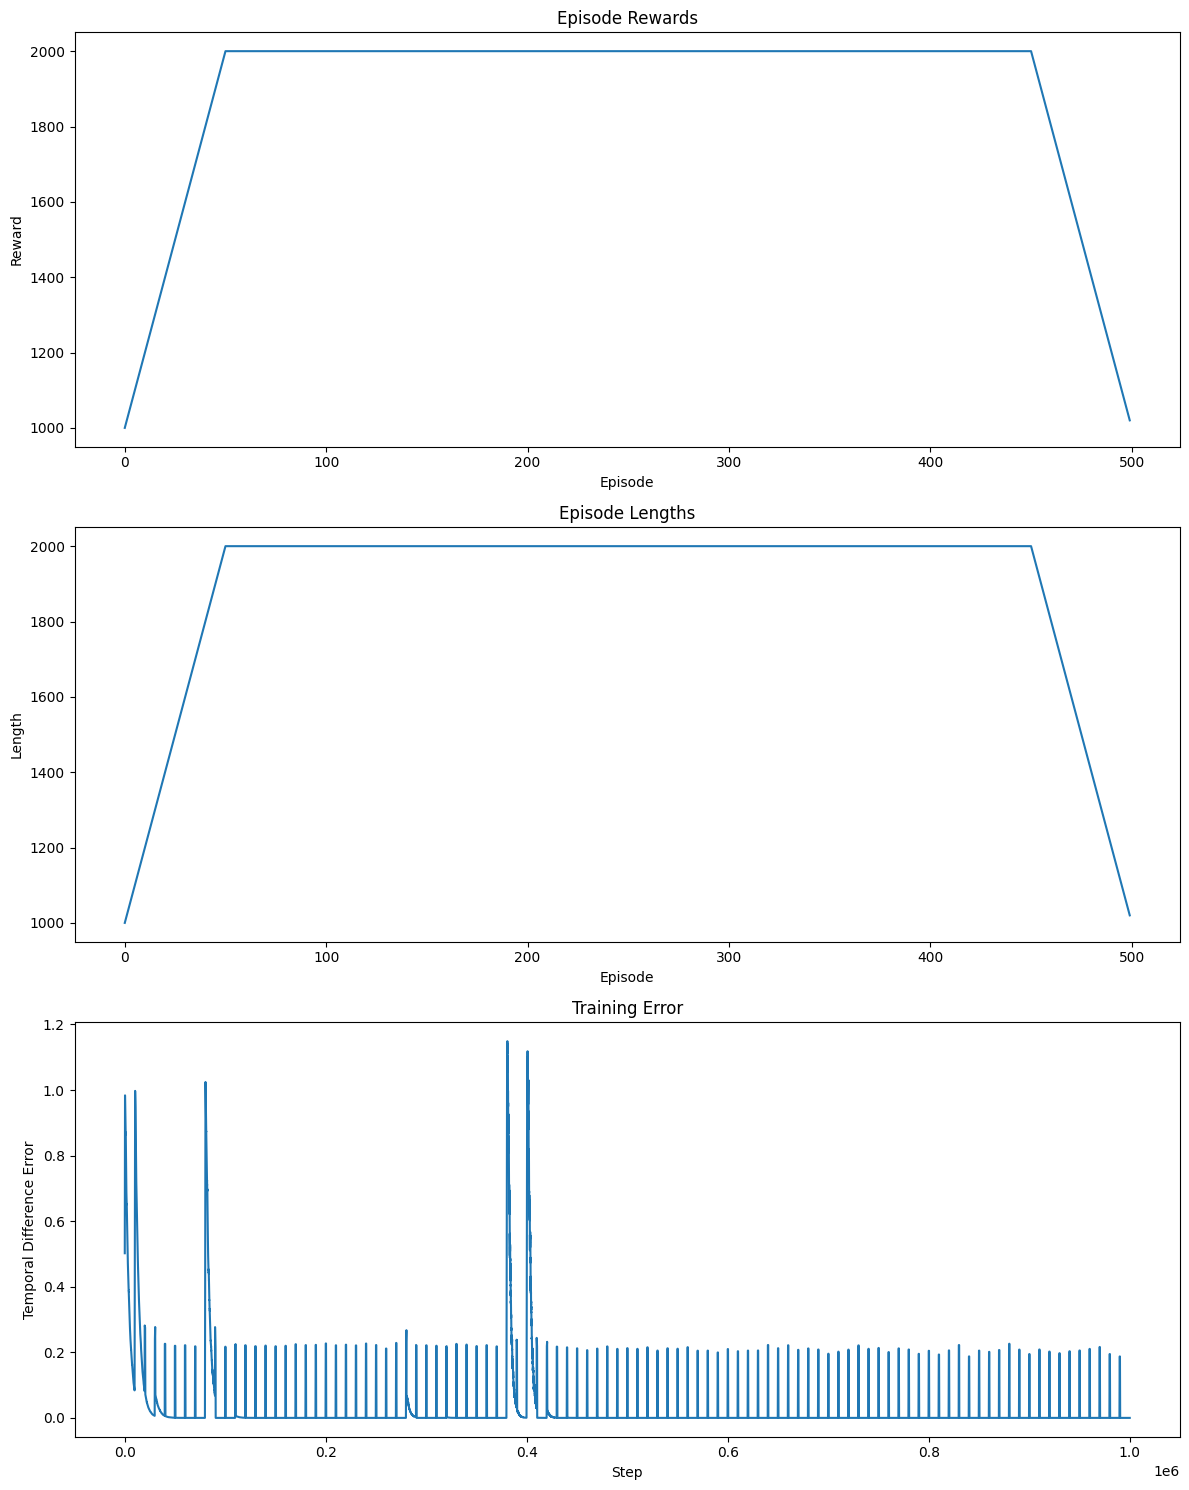

In [ ]:
from matplotlib import pyplot as plt

def get_moving_avgs(arr, window, convolution_mode):
    """Compute moving average to smooth noisy data."""
    return np.convolve(
        np.array(arr).flatten(),
        np.ones(window),
        mode=convolution_mode
    ) / window

#Need to plot two array here, episode rewards and episode lengths

# Smooth over a 500-episode window
rolling_length = 500
fig, axs = plt.subplots(nrows=3, figsize=(12, 15)) # Changed to nrows for better layout


# Episode Rewards
axs[0].set_title("Episode Rewards")
rewards_moving_average = get_moving_avgs(
    rewards,
    rolling_length,
    "same"
)
axs[0].plot(range(len(rewards_moving_average)), rewards_moving_average)
axs[0].set_ylabel("Reward")
axs[0].set_xlabel("Episode")


# Episode Lengths
axs[1].set_title("Episode Lengths")
lengths_moving_average = get_moving_avgs(
    ep_lengths,
    rolling_length,
    "same"
)
axs[1].plot(range(len(lengths_moving_average)), lengths_moving_average)
axs[1].set_ylabel("Length")
axs[1].set_xlabel("Episode")

# Training error (how much we're still learning)
axs[2].set_title("Training Error")
training_error_moving_average = get_moving_avgs(
    agent.training_error,
    rolling_length,
    "same"
)
axs[2].plot(range(len(training_error_moving_average)), training_error_moving_average)
axs[2].set_ylabel("Temporal Difference Error")
axs[2].set_xlabel("Step")

plt.tight_layout()
plt.show()

In [ ]:
# Test the environment
env = CoastingCarEnv()
obs = env.reset()
done = False
for i in range(100):
    action = 1  # Brake
    # print("Before: ")
    # env.render()
    obs, reward, done, _ = env.step(action)
    # print("After")
    env.render()
    print(reward)
    

Position: 9.500000000000002, Velocity: 9.0, Time: 0.9999999999999998
1
Position: 18.000000000000007, Velocity: 8.0, Time: 1.9999999999999996
1
Position: 25.500000000000007, Velocity: 7.000000000000001, Time: 2.999999999999999
1
Position: 32.00000000000001, Velocity: 6.000000000000002, Time: 3.999999999999999
1
Position: 37.500000000000014, Velocity: 5.000000000000002, Time: 4.999999999999999
1
Position: 42.000000000000014, Velocity: 4.000000000000002, Time: 5.999999999999999
1
Position: 45.50000000000002, Velocity: 3.0000000000000018, Time: 6.999999999999999
1
Position: 48.00000000000003, Velocity: 2.0000000000000018, Time: 7.999999999999999
1
Position: 49.500000000000036, Velocity: 1.000000000000001, Time: 9.0
1
Position: 50.000000000000036, Velocity: 1.3322676295501878e-15, Time: 10.0
1
Position: 50.000000000000036, Velocity: 1.3322676295501878e-15, Time: 11.0
1
Position: 50.000000000000036, Velocity: 1.3322676295501878e-15, Time: 12.0
1
Position: 50.000000000000036, Velocity: 1.3322

d:\Reinforcement learning\kyx_parser\.venv\Lib\site-packages\gym\spaces\box.py:127: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(f"Box bound precision lowered by casting to {self.dtype}")
